In [26]:

# Step 1: Install the tools used in our quantum project

!pip -q install pennylane scikit-learn matplotlib


In [27]:

import pennylane as qml
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

print("PennyLane version:", qml.__version__)
print("Setup complete!")


PennyLane version: 0.45.1
Setup complete!


In [28]:

# Step 2: Load and inspect the healthcare dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Classes:", list(data.target_names))

X.head()


Dataset loaded successfully!
Number of samples: 569
Number of features: 30
Classes: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [29]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [30]:

# STEP 3: Build our classical machine-learning baseline

import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load data again so this cell works after reconnecting
data = load_breast_cancer()
X = data.data
y = data.target

# Keep some data unseen during training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Create and train the classical model
classical_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

classical_model.fit(X_train, y_train)

# Test the model on unseen data
classical_predictions = classical_model.predict(X_test)

print("CLASSICAL MODEL RESULTS")
print("Accuracy:", round(accuracy_score(y_test, classical_predictions), 4))
print("Precision:", round(precision_score(y_test, classical_predictions), 4))
print("Recall:", round(recall_score(y_test, classical_predictions), 4))
print("F1 score:", round(f1_score(y_test, classical_predictions), 4))
print("\nDetailed report:")
print(classification_report(y_test, classical_predictions,
                            target_names=data.target_names))


CLASSICAL MODEL RESULTS
Accuracy: 0.979
Precision: 0.9888
Recall: 0.9778
F1 score: 0.9832

Detailed report:
              precision    recall  f1-score   support

   malignant       0.96      0.98      0.97        53
      benign       0.99      0.98      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



In [31]:

# STEP 4: Compare classical and quantum machine learning
# This experiment uses two features and a small subset of the dataset.

import numpy as np
import pennylane as qml
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

# 1. Load a small, reproducible dataset
data = load_breast_cancer()

# Use two measurements: mean radius and mean texture
X = data.data[:, :2]
y = data.target

# Select 100 records, keeping both classes represented
rng = np.random.RandomState(42)
chosen = []

for label in np.unique(y):
    indices = np.where(y == label)[0]
    chosen.extend(rng.choice(indices, size=50, replace=False))

chosen = np.array(chosen)
X, y = X[chosen], y[chosen]

# 2. Split the same records for both models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale using training data only, then map values to circuit angles
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_q = np.clip(X_train_scaled, -3, 3) * (np.pi / 3)
X_test_q = np.clip(X_test_scaled, -3, 3) * (np.pi / 3)

# 3. Train a classical model using the same two features
classical = SVC(kernel="rbf")
classical.fit(X_train_scaled, y_train)
classical_pred = classical.predict(X_test_scaled)

# 4. Define a two-qubit quantum feature map
dev = qml.device("default.qubit", wires=2)

def feature_map(x):
    qml.AngleEmbedding(x, wires=[0, 1], rotation="Y")
    qml.CNOT(wires=[0, 1])
    qml.AngleEmbedding(x, wires=[0, 1], rotation="Z")

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    feature_map(x1)
    qml.adjoint(feature_map)(x2)
    return qml.probs(wires=[0, 1])

def quantum_kernel(x1, x2):
    # Probability of measuring |00> gives the kernel similarity
    return float(kernel_circuit(x1, x2)[0])

# 5. Calculate the quantum training kernel
def make_kernel(A, B, symmetric=False):
    K = np.zeros((len(A), len(B)))

    for i in range(len(A)):
        start = i if symmetric else 0
        for j in range(start, len(B)):
            value = quantum_kernel(A[i], B[j])
            K[i, j] = value
            if symmetric:
                K[j, i] = value

    return K

print("Calculating quantum training kernel...")
start_time = time.time()

K_train = make_kernel(X_train_q, X_train_q, symmetric=True)

print("Calculating quantum test kernel...")
K_test = make_kernel(X_test_q, X_train_q)

# 6. Train and evaluate the quantum-kernel SVM
quantum_model = SVC(kernel="precomputed")
quantum_model.fit(K_train, y_train)
quantum_pred = quantum_model.predict(K_test)

print("\nCOMPARISON RESULTS")
print("Classical accuracy:", round(accuracy_score(y_test, classical_pred), 4))
print("Quantum accuracy:  ", round(accuracy_score(y_test, quantum_pred), 4))
print("Classical F1:      ", round(f1_score(y_test, classical_pred), 4))
print("Quantum F1:        ", round(f1_score(y_test, quantum_pred), 4))
print("Quantum kernel calculation time:",
      round(time.time() - start_time, 2), "seconds")
print("\nExperiment complete!")


Calculating quantum training kernel...
Calculating quantum test kernel...

COMPARISON RESULTS
Classical accuracy: 0.92
Quantum accuracy:   0.76
Classical F1:       0.9231
Quantum F1:         0.7857
Quantum kernel calculation time: 21.59 seconds

Experiment complete!


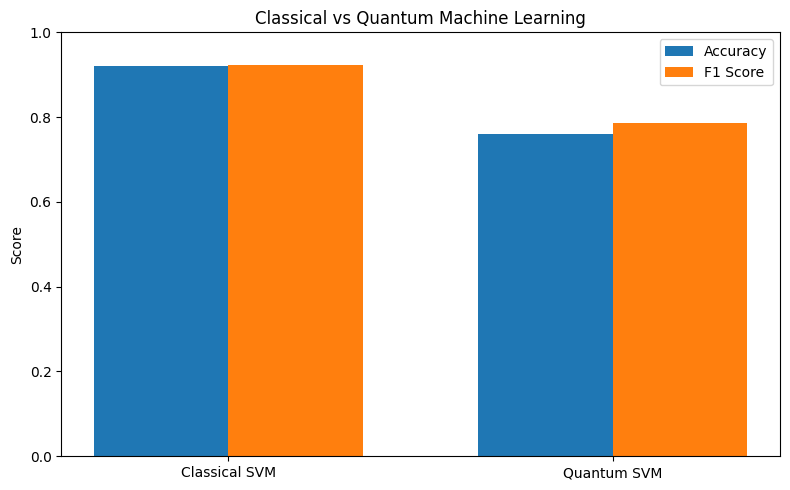

In [32]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

models = ["Classical SVM", "Quantum SVM"]

accuracies = [
    accuracy_score(y_test, classical_pred),
    accuracy_score(y_test, quantum_pred)
]

f1_scores = [
    f1_score(y_test, classical_pred),
    f1_score(y_test, quantum_pred)
]

positions = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(positions - width/2, accuracies, width, label="Accuracy")
plt.bar(positions + width/2, f1_scores, width, label="F1 Score")

plt.xticks(positions, models)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Classical vs Quantum Machine Learning")
plt.legend()
plt.tight_layout()

plt.savefig("model_comparison.png", dpi=200)
plt.show()


Quantum Machine Learning for Healthcare: Breast Cancer Classification

1. Introduction

The goal of this project is to explore how machine learning can help classify breast cancer data. I compared a classical machine-learning model with a quantum-kernel machine-learning model to investigate their performance.

2. Dataset

I used the Breast Cancer Wisconsin dataset available through Scikit-learn. It contains 569 samples and 30 features describing cell characteristics. The labels represent malignant and benign cases.

3. Methodology

I used a Support Vector Machine (SVM) as the classical model. For the quantum approach, I used PennyLane to simulate a quantum circuit and calculate a quantum kernel. This kernel measures similarity between encoded data points and is then used by an SVM to make predictions.

For the small comparison experiment, both models used the same 100 selected samples, two features, and the same training and testing split.

4. Results

The classical SVM achieved 92% accuracy and an F1 score of approximately 0.9231. The quantum-kernel SVM achieved 76% accuracy and an F1 score of approximately 0.7857.

The comparison chart shows that the classical model performed better in this experiment. The results demonstrate that using a quantum kernel does not automatically improve machine-learning performance.

5. Limitations

The quantum circuit was simulated on a classical computer rather than run on physical quantum hardware. The comparison used only two features and a small subset of the dataset, so the results cannot establish how the approach would perform on every dataset. This project is educational research, not a clinically validated diagnostic system.

6. Conclusion

This project helped me explore the differences between classical and quantum machine learning. Although the classical SVM performed better in my experiment, the comparison helped me understand how a quantum kernel can be incorporated into a machine-learning workflow. Future work could test different feature selections, quantum circuits, and data splits.

7. Tools Used

* Python
* Google Colab
* Scikit-learn
* PennyLane
* NumPy
* Matplotlib